In [1]:
from copy import deepcopy
import numpy as np

In [2]:
def f(x):
    return x * x + 3 * x - 2

In [3]:
xs = range(-10, 10)
ys = [f(x) for x in xs]

In [4]:
import matplotlib.pyplot as plt

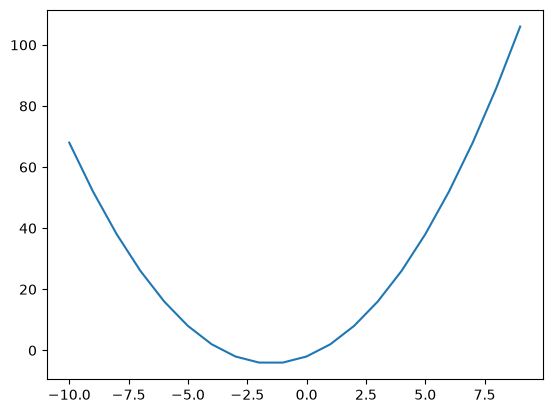

In [5]:
plt.plot(xs, ys)
plt.show()

In [6]:
from abc import ABC, abstractmethod 

In [7]:
class Node(ABC):
    @abstractmethod
    def evaluate(self, x):
        pass
    
    @abstractmethod
    # NAPOMENA: metoda get_random_subtree() može vratiti i koren stabla, čime se omogućava zamena celog 
    # stabla tokom ukrštanja ili mutacije.
    def get_random_subtree(self):
        pass
    
    @abstractmethod
    # Ukoliko ne želimo da dozvolimo zamenu celog stabla, možemo koristiti dodatni argument is_root, 
    # koji označava da li se trenutno nalazimo u korenu stabla.
    def get_random_subtree_without_root(self, is_root):
        pass
    
    @abstractmethod
    def swap_subtrees(self, curr_subtree, new_subtree):
        pass
    
    @staticmethod
    @abstractmethod
    def generate_random_tree(depth):
        pass
    
    @abstractmethod
    def __str__(self):
        pass

In [8]:
class Terminal(Node):
    def __init__(self, value):
        self.value = value
    
    def __str__(self):
        if type(self.value) == str:
            return self.value
        else:
            return str(self.value)
        
    def evaluate(self, x):
        if type(self.value) == str:
            return x
        else:
            return self.value
    
    def get_random_subtree(self):
        return self
    
    def get_random_subtree_without_root(self, is_root):
        return self
    
    def swap_subtrees(self, curr_subtree, new_subtree):
        if self == curr_subtree:
            return new_subtree
        else:
            return self
    
    def generate_random_tree(depth):
        if depth != 1:
            raise ValueError("Drvo mora biti dubine 1!")
        if random.random() < 0.5:
            return Terminal(random.randrange(-10, 10))
        else:
            return Terminal('x')

In [9]:
import random

In [10]:
class Operator(Node):
    # dozvoljeni operatori: +, -, *
    def __init__(self, op, left, right):
        self.op = op
        self.left = left
        self.right = right
    
    def __str__(self):
        return f"({self.left.__str__()} {self.op} {self.right.__str__()})"
    
    def evaluate(self, x):
        left_val = self.left.evaluate(x)
        right_val = self.right.evaluate(x)
        
        match self.op:
            case '+':
                return left_val + right_val
            case '-':
                return left_val - right_val
            case '*':
                return left_val * right_val
    
    def get_random_subtree(self):
        r = random.random()
        
        if r < 0.33:
            return self
        elif r < 0.66:
            return self.left.get_random_subtree()
        else:
            return self.right.get_random_subtree()
        
    def get_random_subtree_without_root(self, is_root):
        if is_root:
            if random.random() < 0.5:
                return self.left.get_random_subtree_without_root(is_root = False)
            else:
                return self.right.get_random_subtree_without_root(is_root = False)
        r = random.random()
        
        if r < 0.33:
            return self
        elif r < 0.66:
            return self.left.get_random_subtree()
        else:
            return self.right.get_random_subtree()
        

    def swap_subtrees(self, curr_subtree, new_subtree):
        if self == curr_subtree:
            return new_subtree
        
        left = self.left.swap_subtrees(curr_subtree, new_subtree)
        right = self.right.swap_subtrees(curr_subtree, new_subtree)
        
        return Operator(self.op, left, right)
    
    def generate_random_tree(depth):
        if depth == 1:
            if random.random() < 0.5:
                return Terminal(random.randrange(-10, 10))
            else:
                return Terminal('x')
        
        op = random.sample(['+', '-', '*'], 1)[0]
        left = Operator.generate_random_tree(depth - 1)
        right = Operator.generate_random_tree(depth - 1)
        
        return Operator(op, left, right)

In [11]:
x = Operator.generate_random_tree(3)
str(x)

'((3 + 0) * (7 + 9))'

In [12]:
rst = x.get_random_subtree()
str(rst)

'9'

In [13]:
new_tree = Operator.generate_random_tree(2)
str(new_tree)

'(x * x)'

In [14]:
x = x.swap_subtrees(rst, new_tree)
str(x)

'((3 + 0) * (7 + (x * x)))'

In [15]:
class Individual:
    def __init__(self, depth, xs, ys):
        self.code = Operator.generate_random_tree(random.randrange(1, depth))
        self.fitness = self.calc_fitness(xs, ys)
    
    def calc_fitness(self, xs, ys):
        mse = 0
        
        for x, y in zip(xs, ys):
            y_pred = self.code.evaluate(x)
            mse += (y_pred - y) ** 2
        return mse / len(xs)

    def __lt__(self, other):
        return self.fitness < other.fitness

In [16]:
def rank_selection(population):
    ranks = np.arange(len(population), 0, -1)
    selection_probs = ranks / sum(ranks)
    
    chosen = np.random.choice(population, p = selection_probs, size = 2, replace = False)
    
    return chosen[0], chosen[1]

In [17]:
def crossover(parent1, parent2):
    child1 = deepcopy(parent1)
    child2 = deepcopy(parent2)
    
    c1_subtree = child1.code.get_random_subtree()
    c2_subtree = child2.code.get_random_subtree()
    
    child1.code = child1.code.swap_subtrees(c1_subtree, c2_subtree)
    child2.code = child2.code.swap_subtrees(c2_subtree, c1_subtree)
    
    return child1, child2

In [18]:
def mutation(child, mutation_prob):
    c1 = child.code.get_random_subtree()
    
    if random.random() < mutation_prob:
        new_subtree = Operator.generate_random_tree(random.randrange(1, 4))
    
        child.code = child.code.swap_subtrees(c1, new_subtree)

In [19]:
def gp(xs, ys, max_depth, population_size, elitism_size, mutation_prob, num_iters):
    population = [Individual(max_depth, xs, ys) for _ in range(population_size)]
    
    elitism = int(population_size * elitism_size)
    
    if (population_size - elitism) %  2:
        elitism += 1
    
    for _ in range(num_iters):
        population.sort()
        if population[0].fitness == 0.0:
            break
        new_population = deepcopy(population[:elitism])
        
        for _ in range(int((population_size - elitism) / 2)):
            parent1, parent2 = rank_selection(population)
            child1, child2 = crossover(parent1, parent2)
            
            mutation(child1, mutation_prob)
            mutation(child2, mutation_prob)
            
            child1.fitness = child1.calc_fitness(xs, ys)
            child2.fitness = child2.calc_fitness(xs, ys)
            
            new_population.append(child1)
            new_population.append(child2)
        population = deepcopy(new_population) # NAPOMENA: deepcopy nije neophodan na ovom mestu u kodu
    return min(population)

In [20]:
best_individual = gp(xs, ys, 4, 200, 0.2, 0.05, 100)
print(best_individual.fitness)
print(best_individual.code)

0.0
(((x * x) + ((x + x) + x)) + -2)
